# EDA · Generación de residuos en la UE

**Objetivo.** Explorar la evolución temporal, diferencias entre países, peligrosidad, relación con el PIB y peso de las actividades económicas en la generación de residuos.

**Fuente principal:** Eurostat, `env_wasgen_linear.csv.gz` (el mismo fichero utilizado en `Limpieza_generacion.ipynb`).

## 0. Preparación y carga

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, mannwhitneyu
import plotly.express as px

# Estilo común para todos los gráficos del proyecto
import matplotlib as mpl

PALETA_RESIDUOS = {
    "azul": "#264653",
    "verde": "#2A9D8F",
    "amarillo": "#E9C46A",
    "naranja": "#F4A261",
    "coral": "#E76F51",
    "gris": "#6C757D",
}

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font="DejaVu Sans",
    palette=[
        PALETA_RESIDUOS["azul"],
        PALETA_RESIDUOS["verde"],
        PALETA_RESIDUOS["amarillo"],
        PALETA_RESIDUOS["naranja"],
        PALETA_RESIDUOS["coral"],
        PALETA_RESIDUOS["gris"],
    ],
)

mpl.rcParams.update({
    "figure.figsize": (10, 5.8),
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#D9E1E5",
    "axes.labelcolor": "#35434A",
    "axes.titlecolor": "#20343B",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "axes.titlepad": 14,
    "font.size": 10,
    "xtick.color": "#52636B",
    "ytick.color": "#52636B",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "grid.color": "#DCE4E8",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.75,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "lines.linewidth": 2.4,
    "lines.markersize": 6,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Mantener una apariencia equivalente en los gráficos interactivos de Plotly
PLOTLY_TEMPLATE = "plotly_white"


In [2]:
# Importamos los datos
df = pd.read_csv('./Data/gen_residuos.csv')

In [3]:
df.head()

,pais,year,peligrosidad,actividad,residuo,kg_per_capita,toneladas,obs_flag,conf_status
0,Austria,2004,Peligrosos,"Agricultura, ganadería, silvicultura y pesca","Residuos ácidos, alcalinos o salinos",0.0,1.0,NaN,NaN
1,Austria,2006,Peligrosos,"Agricultura, ganadería, silvicultura y pesca","Residuos ácidos, alcalinos o salinos",0.0,0.0,NaN,NaN
2,Austria,2008,Peligrosos,"Agricultura, ganadería, silvicultura y pesca","Residuos ácidos, alcalinos o salinos",0.0,0.0,NaN,NaN
3,Austria,2010,Peligrosos,"Agricultura, ganadería, silvicultura y pesca","Residuos ácidos, alcalinos o salinos",0.0,0.0,NaN,NaN
4,Austria,2012,Peligrosos,"Agricultura, ganadería, silvicultura y pesca","Residuos ácidos, alcalinos o salinos",0.0,0.0,NaN,NaN


## 1. Calidad y cobertura de los datos
Comprobamos dimensiones, tipos, valores ausentes, cobertura temporal y categorías.

In [4]:
print("Dimensiones:", df.shape)
print(df.info())
display(df.isna().mean().sort_values(ascending=False).to_frame("proporción_NA").head(12))
print(df[["year","pais","peligrosidad","actividad","residuo"]].nunique())
print(df.groupby("year")["pais"].nunique().rename("nº geografías"))

Dimensiones: (688573, 9)
<class 'pandas.DataFrame'>
RangeIndex: 688573 entries, 0 to 688572
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   pais           688573 non-null  str    
 1   year           688573 non-null  int64  
 2   peligrosidad   688573 non-null  str    
 3   actividad      688573 non-null  str    
 4   residuo        688573 non-null  str    
 5   kg_per_capita  603137 non-null  float64
 6   toneladas      603137 non-null  float64
 7   obs_flag       95725 non-null   str    
 8   conf_status    11846 non-null   str    
dtypes: float64(2), int64(1), str(6)
memory usage: 47.3 MB
None


,proporción_NA
conf_status,0.982796
obs_flag,0.860981
kg_per_capita,0.124077
toneladas,0.124077
pais,0.000000
residuo,0.000000
actividad,0.000000
peligrosidad,0.000000
year,0.000000


year            11
pais            28
peligrosidad     3
actividad       22
residuo         45
dtype: int64
year
2004    28
2006    28
2008    28
2010    28
2012    28
2014    28
2016    28
2018    28
2020    28
2022    28
2024    27
Name: nº geografías, dtype: int64


## 2. ¿Ha aumentado la generación de residuos en la UE?
Se usa el total de residuos y el agregado de todas las actividades y hogares. Se muestran kg per cápita y toneladas en gráficos separados.

In [5]:
UE = "Unión Europea (UE-27)"

In [6]:
# Nos quedamos con: total de residuos y todas las actividades
base_total = df[
    (df["residuo"] == "Total de residuos") &
    (df["actividad"] == "Todas las actividades NACE más los hogares")
].copy()

# Primero analizamos la UE en general
base_ue = base_total[base_total["pais"] == UE].copy()

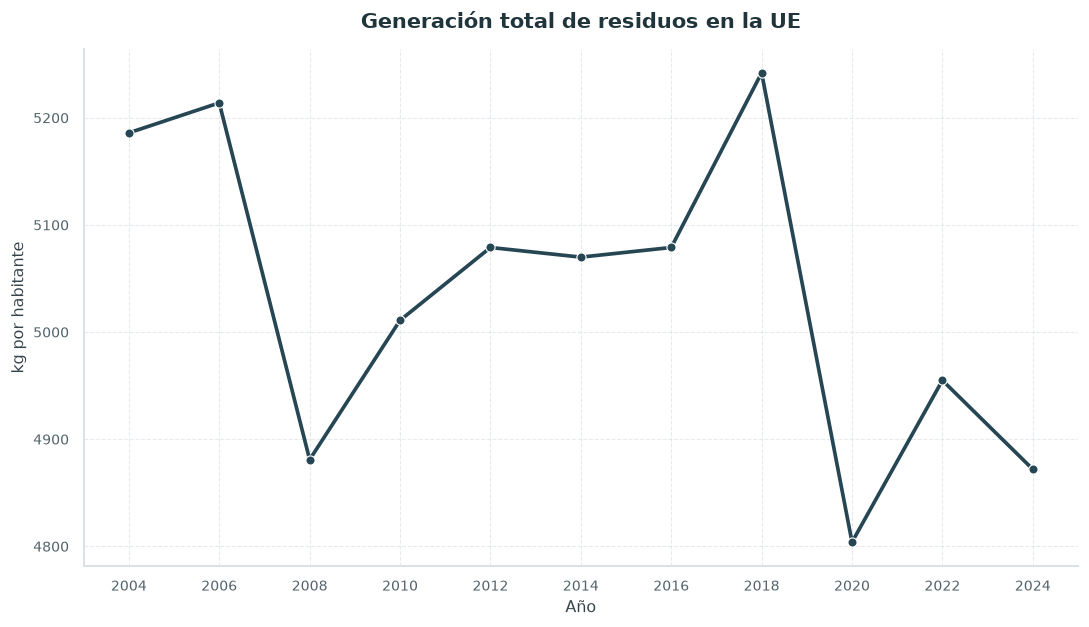

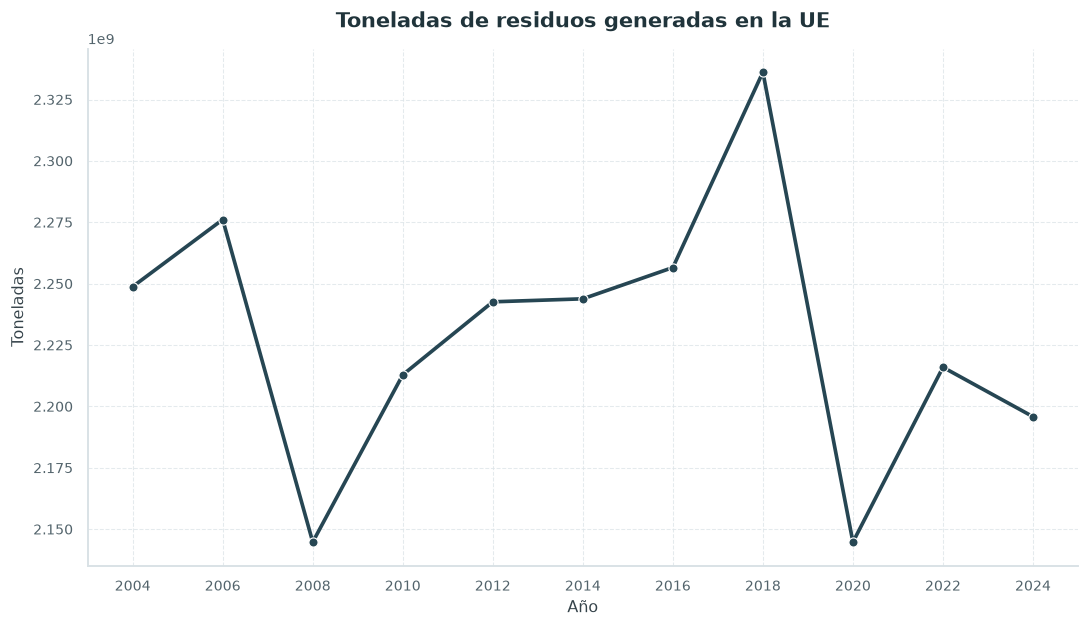

In [7]:
ue_general = base_ue[base_ue["peligrosidad"] == "Total (peligrosos y no peligrosos)"]

fig, ax = plt.subplots()
sns.lineplot(
    data=ue_general, 
    x="year", 
    y="kg_per_capita", 
    marker="o", 
    ax=ax
    )

ax.set(
    title="Generación total de residuos en la UE", 
    xlabel="Año", 
    ylabel="kg por habitante"
    )
ax.set_xticks(ue_general["year"])
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
sns.lineplot(
    data=ue_general, 
    x="year", 
    y="toneladas", 
    marker="o", 
    ax=ax)
ax.set(
    title="Toneladas de residuos generadas en la UE", 
    xlabel="Año", 
    ylabel="Toneladas"
    )
ax.set_xticks(ue_general["year"])
plt.tight_layout()
plt.show()

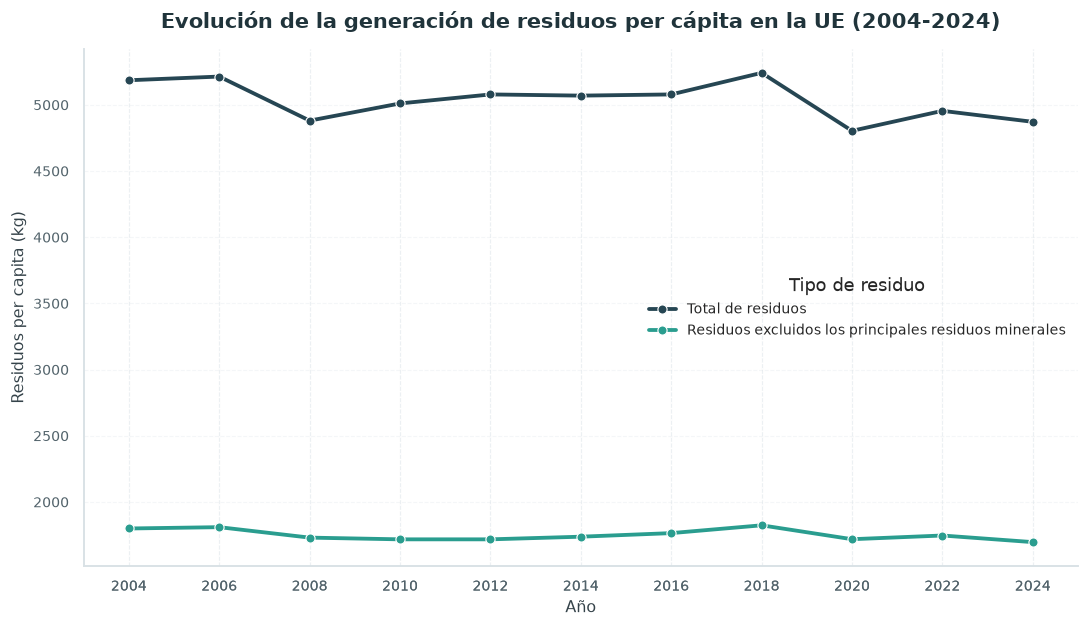

In [8]:
# Como los residuos minerales suelen ser bastante grandes, miramos también la evolución sin contarlos
ue_gen_sinmin = df[
    (df["residuo"].isin(["Residuos excluidos los principales residuos minerales", "Total de residuos"])) &
    (df["actividad"] == "Todas las actividades NACE más los hogares") &
    (df["peligrosidad"] == "Total (peligrosos y no peligrosos)") &
    (df["pais"] == UE)
].copy()



sns.lineplot(
    data=ue_gen_sinmin,
    x="year",
    y="kg_per_capita",
    hue="residuo",
    marker="o",
    linewidth=2.5,
)

plt.title("Evolución de la generación de residuos per cápita en la UE (2004-2024)", fontsize=14)
plt.xlabel("Año")
plt.ylabel("Residuos per capita (kg)")
plt.xticks(ue_gen_sinmin["year"])
plt.legend(title="Tipo de residuo")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

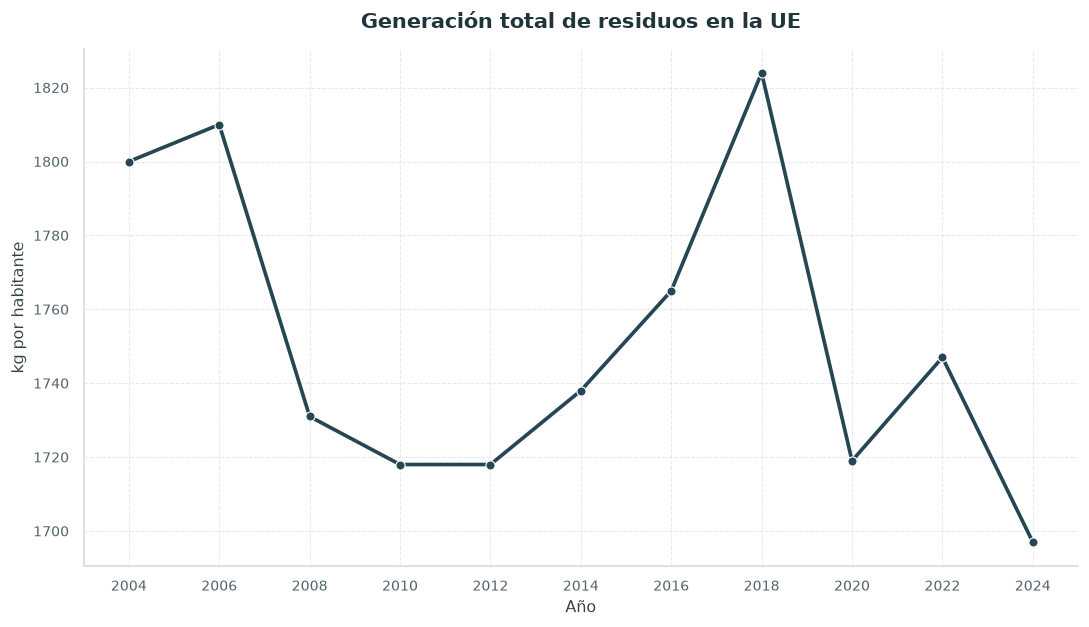

In [9]:
# Como hay mucha diferencia entre uno y otro, miramos solo la evolución de los residuos excluyendo los minerales
ue_sinmin = ue_gen_sinmin[
    (ue_gen_sinmin["residuo"] == "Residuos excluidos los principales residuos minerales")
].copy()

fig, ax = plt.subplots()
sns.lineplot(
    data=ue_sinmin, 
    x="year", 
    y="kg_per_capita", 
    marker="o", 
    ax=ax)
ax.set(
    title="Generación total de residuos en la UE", 
    xlabel="Año", 
    ylabel="kg por habitante"
    )
ax.set_xticks(ue_sinmin["year"])
plt.tight_layout()
plt.show()

### Evolución por países

In [10]:
paises_general = base_total[base_total["peligrosidad"] == "Total (peligrosos y no peligrosos)"]

fig = px.line(
    paises_general,
    x="year",
    y="kg_per_capita",
    color="pais",
    markers=True,
    color_discrete_sequence=px.colors.qualitative.T10
)

fig.update_traces(
    line=dict(width=1.8),
    marker=dict(size=7)
)

fig.update_layout(
    title="Evolución de la generación total de residuos por país (UE) (2004-2024)",
    title_font_size=15,

    xaxis_title= "Año",
    yaxis_title= "Residuos per capita (kg)",

    legend=dict(
        title="País",
        x=1.02,
        y=1,
        xanchor="left",
        yanchor="top"
    ),

    template=PLOTLY_TEMPLATE
)

fig.update_xaxes(showgrid=True, gridcolor="lightgray")
fig.update_yaxes(showgrid=True, gridcolor="lightgray")

fig.show()

In [11]:
# Como hemos visto anteriormente, los residuos minerales tienen mucho peso. Repetimos el gráfico pero excluyendo los residuos minerales
paises_sinmin = df[
    (df["residuo"] == "Residuos excluidos los principales residuos minerales") &
    (df["actividad"] == "Todas las actividades NACE más los hogares") &
    (df["peligrosidad"] == "Total (peligrosos y no peligrosos)")
].copy()

fig = px.line(
    paises_sinmin,
    x="year",
    y="kg_per_capita",
    color="pais",
    markers=True,
    color_discrete_sequence=px.colors.qualitative.T10
)

fig.update_traces(
    line=dict(width=1.8),
    marker=dict(size=7)
)

fig.update_layout(
    title="Evolución de la generación total de residuos por país (UE) (2004-2024)",
    title_font_size=15,

    xaxis_title= "Año",
    yaxis_title= "Residuos per capita (kg)",

    legend=dict(
        title="País",
        x=1.02,
        y=1,
        xanchor="left",
        yanchor="top"
    ),

    template=PLOTLY_TEMPLATE
)

fig.update_xaxes(showgrid=True, gridcolor="lightgray")
fig.update_yaxes(showgrid=True, gridcolor="lightgray")

fig.show()

## 3. ¿Ha disminuido la proporción de residuos peligrosos?
Calculamos el porcentaje de toneladas peligrosas sobre toneladas totales para cada año. 

In [12]:
res_peligrosos = base_ue[base_ue["peligrosidad"] == 'Peligrosos']

In [13]:
# Comprobamos si hay algún "flag"
res_peligrosos[['obs_flag', 'conf_status']].notna().sum().to_frame(name='valores_no_nan')

,valores_no_nan
obs_flag,1
conf_status,0


In [14]:
res_peligrosos[~res_peligrosos["obs_flag"].isna()]

,pais,year,peligrosidad,actividad,residuo,kg_per_capita,toneladas,obs_flag,conf_status
18631,Unión Europea (UE-27),2024,Peligrosos,Todas las actividades NACE más los hogares,Total de residuos,286.0,128900000.0,i,NaN


In [15]:
ue_general[['obs_flag', 'conf_status']].notna().sum().to_frame(name='valores_no_nan')

,valores_no_nan
obs_flag,1
conf_status,0


In [16]:
ue_general[~ue_general["obs_flag"].isna()]

,pais,year,peligrosidad,actividad,residuo,kg_per_capita,toneladas,obs_flag,conf_status
239839,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Total de residuos,4872.0,2.195830e+09,i,NaN


In [17]:
# En ambos casos el valor de 2024 ha sido imputado por Eurostat

In [18]:
# Unimos ambas series por año
evo_peligrosos = res_peligrosos[['year', 'toneladas']].merge(ue_general[['year', 'toneladas']],
    on='year',
    suffixes=('_peligrosos', '_total')
)

# Calculamos porcentaje
evo_peligrosos['porcentaje'] = evo_peligrosos['toneladas_peligrosos'] / evo_peligrosos['toneladas_total'] * 100

evo_peligrosos

,year,toneladas_peligrosos,toneladas_total,porcentaje
0,2004,80760000.0,2.248790e+09,3.591265
1,2006,93100000.0,2.276120e+09,4.090294
2,2008,87770000.0,2.144780e+09,4.092261
3,2010,90810000.0,2.212890e+09,4.103683
4,2012,89590000.0,2.242610e+09,3.994899
5,2014,89270000.0,2.243830e+09,3.978465
6,2016,94580000.0,2.256580e+09,4.191298
7,2018,126460000.0,2.336160e+09,5.413157
8,2020,112160000.0,2.144750e+09,5.229514
9,2022,119400000.0,2.215960e+09,5.388184


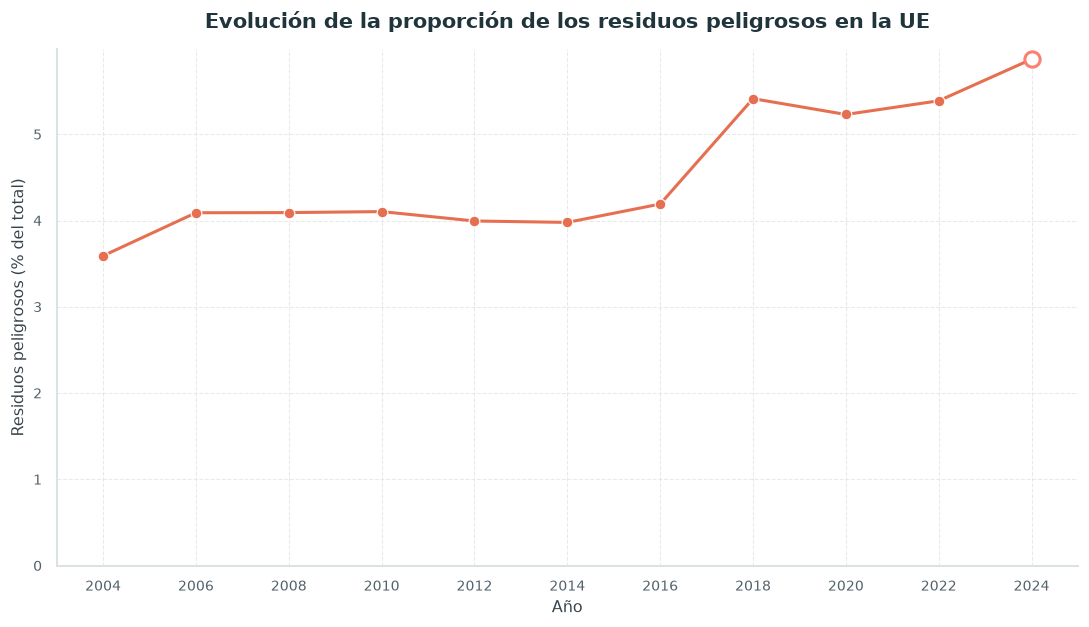

In [19]:
fig, ax = plt.subplots()


sns.lineplot(
    data=evo_peligrosos,
    x="year", 
    y="porcentaje", 
    marker="o", 
    color=PALETA_RESIDUOS["coral"],
    linewidth=2,
    markersize=7,
    ax=ax
)

# Para marcar el dato de 2024 diferente
dato_2024 = evo_peligrosos[evo_peligrosos["year"] == 2024]

sns.scatterplot(
    data=dato_2024,
    x="year",
    y="porcentaje",
    marker="o",         
    s=100,              
    color="white",      
    edgecolor="salmon",
    linewidth=2,        
    zorder=5,           
    ax=ax
)

ax.set(
    title="Evolución de la proporción de los residuos peligrosos en la UE", 
    xlabel="Año", 
    ylabel="Residuos peligrosos (% del total)",
    ylim=(0, None)
)
ax.set_xticks(evo_peligrosos["year"])
plt.tight_layout()
plt.show()

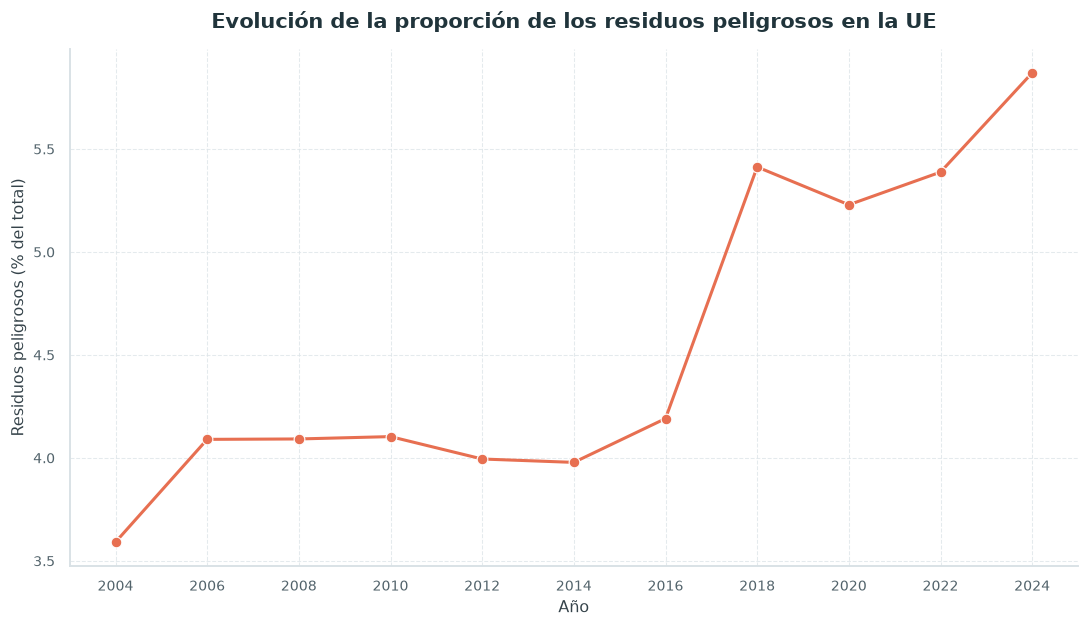

In [20]:
fig, ax = plt.subplots()

sns.lineplot(
    data=evo_peligrosos,
     x="year", 
     y="porcentaje", 
     marker="o", 
     color=PALETA_RESIDUOS["coral"],
     linewidth=2,
     markersize=7
     )

ax.set(
    title="Evolución de la proporción de los residuos peligrosos en la UE", 
    xlabel="Año", 
    ylabel="Residuos peligrosos (% del total)"
    )
ax.set_xticks(evo_peligrosos["year"])
plt.tight_layout()
plt.show()

## 4. Comparación entre países
Comparamos la generación de residuos entre países para 2024. El análisis per cápita evita que el tamaño poblacional domine la comparación.

,pais,kg_per_capita,toneladas
239850,Finlandia,21774.0,1.223671e+08
240047,Suecia,17174.0,1.815217e+08
239773,Bulgaria,14324.0,9.226819e+07
239949,Luxemburgo,12165.0,8.236110e+06
239828,Estonia,10239.0,1.405206e+07
239751,Austria,7186.0,6.595058e+07
239960,Malta,5968.0,3.394916e+06
239762,Bélgica,5909.0,7.002762e+07
239971,Países Bajos,5847.0,1.052089e+08
239839,Unión Europea (UE-27),4872.0,2.195830e+09


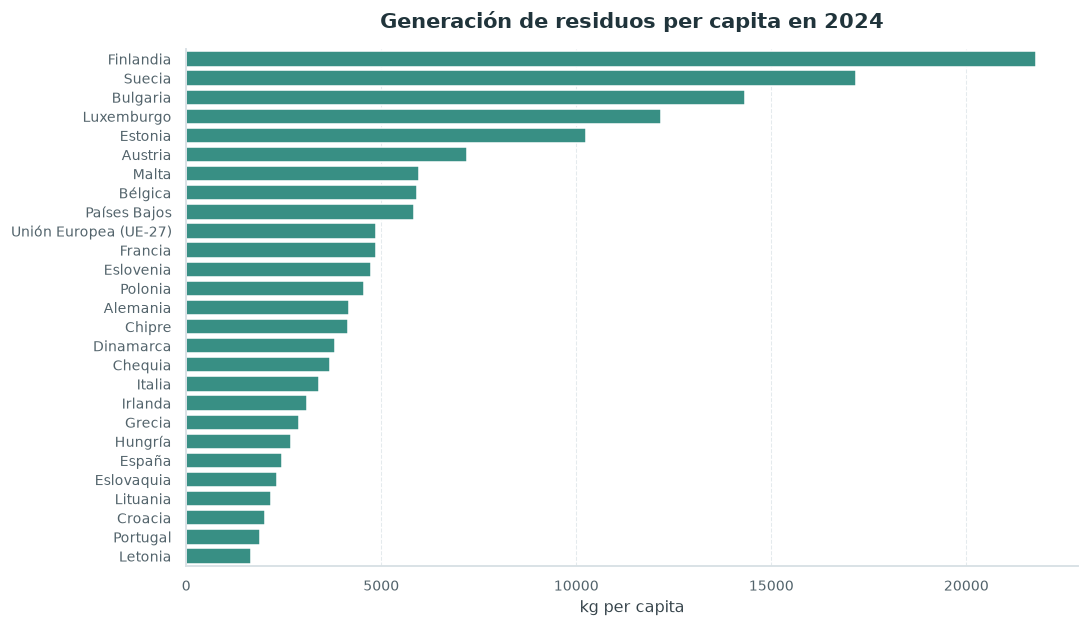

In [21]:
paises_2024 = base_total[
    (base_total["year"] == 2024) &
    (base_total["peligrosidad"] == "Total (peligrosos y no peligrosos)")
].sort_values(by = "kg_per_capita", ascending = False)

display(paises_2024[["pais","kg_per_capita","toneladas"]])


sns.barplot(
    data=paises_2024, 
    x="kg_per_capita", 
    y="pais", 
    color=PALETA_RESIDUOS["verde"])
plt.title(f"Generación de residuos per capita en 2024")
plt.xlabel("kg per capita"); plt.ylabel("")
plt.tight_layout(); plt.show()

## NOTAS:
El anterior gráfico muestra los residuos totales generados per capita.
> Para ver el análisis de los residuos totales excluyendo los minerales, se puede consultar el mapa que está tanto en el archivo `mapa_residuos_UE_2024.html` tanto en el notebook `mapas`.


> Como comentario: 
>> Destaca Estonia. Al parecer, es por el oil-shale (a lo que debe ponerle fin debido a políticas climáticas de la UE entre 2030 y 2035).

Exportamos los datos de los residuos generados por cada país en 2024 para poder analizarlos luego conjuntamente con los residuos tratados.

In [22]:
paises_2024.to_csv("./Data/gen_2024.csv", index=False)

## 5. ¿Qué actividades generan más residuos?
Para evitar sumar categorías solapadas, se filtra `Total de residuos` y se excluye el agregado `Todas las actividades NACE más los hogares`. Se comparan toneladas por actividad para 2004 y el último año disponible. La cobertura de actividades puede cambiar entre años.

year,2004,2024
actividad,,
"Agricultura, ganadería, silvicultura y pesca",63350000.0,25350000.0
"Captación, depuración y distribución de agua; recogida y tratamiento de aguas residuales; actividades de descontaminación y otros servicios de gestión de residuos",5880000.0,27610000.0
Comercio al por mayor de chatarra y productos de desecho,4060000.0,12980000.0
Construcción,667020000.0,839600000.0
Coquerías y refino de petróleo,3450000.0,5710000.0
"Fabricación de muebles; joyería, instrumentos musicales, juguetes; reparación e instalación de maquinaria y equipo",4460000.0,5350000.0
Fabricación de otros productos minerales no metálicos,23980000.0,18720000.0
"Fabricación de productos informáticos, electrónicos y ópticos, material y equipo eléctrico, vehículos de motor y otro material de transporte",20070000.0,17690000.0
Hogares,179960000.0,195810000.0


C:\Users\ngo1\AppData\Local\Temp\ipykernel_14480\3921730554.py:20: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


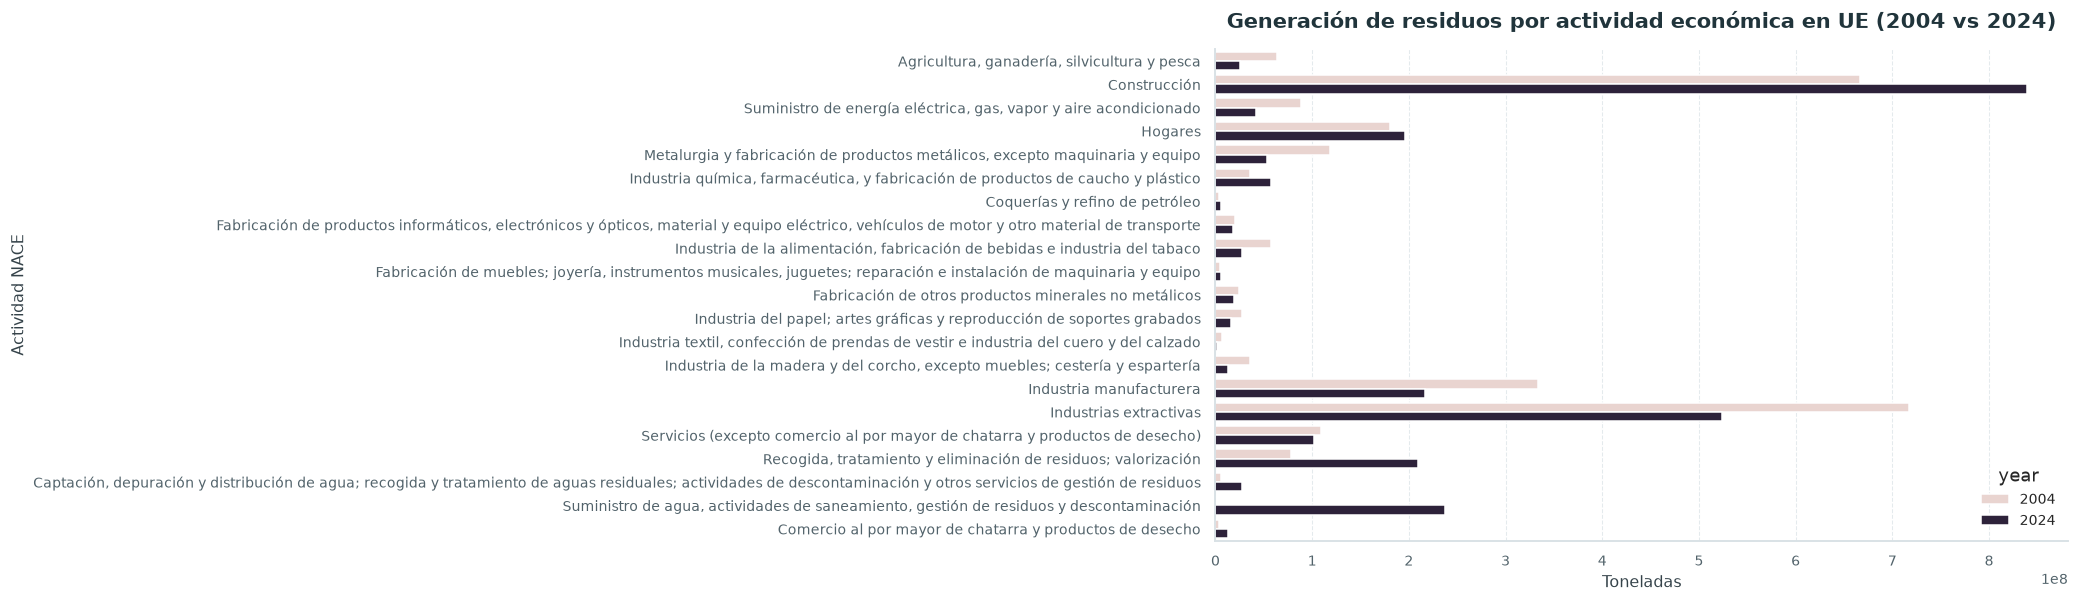

In [23]:
actividades_ue = df[
    (df["pais"] == UE) &
    (df["residuo"] == "Total de residuos") &
    (df["peligrosidad"] == "Total (peligrosos y no peligrosos)") &
    (df["actividad"] != "Todas las actividades NACE más los hogares") &
    (df["year"].isin([2004, 2024]))
].copy()

display(actividades_ue.pivot_table(index="actividad", columns="year", values="toneladas", aggfunc="sum"))


sns.barplot(
    data=actividades_ue, 
    x="toneladas", 
    y="actividad", 
    hue="year")
plt.title("Generación de residuos por actividad económica en UE (2004 vs 2024)")
plt.xlabel("Toneladas")
plt.ylabel("Actividad NACE")
plt.tight_layout()
plt.show()

In [24]:
actividades_2024 = actividades_ue[actividades_ue["year"] == 2024]

In [25]:
fig = px.treemap(
    actividades_2024,
    path=[
        "actividad"
    ],
    values="toneladas",
    hover_data=[
        "kg_per_capita"
    ],  # Para mostrar los kg por cápita al pasar el ratón por encima
    title="Distribución de Residuos Generados en la UE por Actividad Económica (2024)",
    color="toneladas", 
    color_continuous_scale="Viridis",
)

fig.update_layout(margin=dict(t=50, l=25, r=25, b=25))

fig.show()

## Tipos de residuos más generados

In [26]:
tipos_res_2024 = df[
    (df["pais"] == UE) &
    (df["residuo"] != "Total de residuos") &
    (df["peligrosidad"] == "Total (peligrosos y no peligrosos)") &
    (df["actividad"] == "Todas las actividades NACE más los hogares") &
    (df["year"] == 2024)
]

In [27]:
# Hacemos filtrado de las categorías --> quitamos las que engloban a otras
categorias_treemap = [
    "Residuos minerales de construcción y demolición",
    "Tierras y suelos",
    "Residuos domésticos y similares",
    "Residuos de papel y cartón",
    "Residuos de combustión",
    "Residuos metálicos mezclados férreos y no férreos",
    "Residuos de clasificación",
    "Residuos de madera",
    "Residuos de plástico",
    "Residuos animales y mezclados de alimentos",
]

# Filtramos la tabla para quedarnos solo con las categorías
df_ue_treemap = tipos_res_2024[tipos_res_2024["residuo"].isin(categorias_treemap)]

In [28]:
df_ue_treemap

,pais,year,peligrosidad,actividad,residuo,kg_per_capita,toneladas,obs_flag,conf_status
230854,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Residuos animales y mezclados de alimentos,57.0,25700000.0,i,NaN
232277,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Residuos de combustión,127.0,57340000.0,i,NaN
234510,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Residuos domésticos y similares,276.0,124540000.0,i,NaN
235320,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Residuos metálicos mezclados férreos y no férreos,24.0,10830000.0,i,NaN
235934,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Residuos minerales de construcción y demolición,717.0,322960000.0,i,NaN
237021,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Residuos de papel y cartón,96.0,43190000.0,i,NaN
237328,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Residuos de plástico,49.0,22080000.0,i,NaN
238668,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Tierras y suelos,1075.0,484560000.0,i,NaN
238918,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Residuos de clasificación,207.0,93120000.0,i,NaN
241290,Unión Europea (UE-27),2024,Total (peligrosos y no peligrosos),Todas las actividades NACE más los hogares,Residuos de madera,105.0,47240000.0,i,NaN


In [29]:
fig = px.treemap(
    df_ue_treemap,
    path=[
        "residuo"
    ], 
    values="toneladas",
    hover_data=[
        "kg_per_capita"
    ], 
    title="Distribución de Residuos Generados en la UE por Tipo de Material (2024)",
    color="toneladas", 
    color_continuous_scale="Viridis", 
)

fig.update_layout(margin=dict(t=50, l=25, r=25, b=25))

fig.show()

## 6. Relación entre crecimiento económico y generación de residuos
Analizamos si el crecimiento económico tiene alguna relación con la generación de residuos. Para ello, importamos los datos del PIB real de `Data/gdp_pc.csv`. Se analiza asociación contemporánea y evolución indexada a 100 por país.

In [30]:
gdp_pc = pd.read_csv('./Data/gdp_pc.csv')

In [31]:
gdp_pc.head()

,pais,year,gdp_pc
0,Austria,2000,37880
1,Austria,2001,38230
2,Austria,2002,38610
3,Austria,2003,38880
4,Austria,2004,39620


In [32]:
todo_ue_general = df[
 (df["residuo"] == "Total de residuos") &
 (df["peligrosidad"] == "Total (peligrosos y no peligrosos)") &
 (df["actividad"] == "Todas las actividades NACE más los hogares")
]

todo_ue_general = todo_ue_general.drop(columns = ["peligrosidad", "actividad", "residuo"])

In [33]:
residuos_gdp = pd.merge(todo_ue_general, gdp_pc, on=["pais", "year"], how="left")

residuos_gdp

,pais,year,kg_per_capita,toneladas,obs_flag,conf_status,gdp_pc
0,Austria,2004,6488.0,53020950.0,NaN,NaN,39620
1,Austria,2006,6565.0,54286603.0,NaN,NaN,41370
2,Austria,2008,6767.0,56308766.0,NaN,NaN,43270
3,Austria,2010,5596.0,46799579.0,NaN,NaN,42280
4,Austria,2012,5699.0,48045089.0,NaN,NaN,43450
...,...,...,...,...,...,...,...
302,Suecia,2016,14272.0,141625718.0,NaN,NaN,46220
303,Suecia,2018,13628.0,138667585.0,NaN,NaN,46700
304,Suecia,2020,14664.0,151823910.0,NaN,NaN,46180
305,Suecia,2022,15627.0,163881439.0,NaN,NaN,48390


In [34]:
residuos_gdp[['obs_flag', 'conf_status']].notna().sum().to_frame(name='valores_no_nan')

,valores_no_nan
obs_flag,17
conf_status,0


In [35]:
residuos_gdp[~residuos_gdp['obs_flag'].isna()]

,pais,year,kg_per_capita,toneladas,obs_flag,conf_status,gdp_pc
12,Bélgica,2006,5627.0,5.935172e+07,e,NaN,38810
62,Chequia,2018,3560.0,3.784761e+07,b,NaN,21320
98,Unión Europea (UE-27),2024,4872.0,2.195830e+09,i,NaN,33850
110,Francia,2004,4743.0,2.965809e+08,i,NaN,33300
111,Francia,2006,4923.0,3.122978e+08,i,NaN,34360
142,Grecia,2024,2894.0,3.002735e+07,p,NaN,19310
143,Hungría,2004,2440.0,2.466092e+07,e,NaN,10570
144,Hungría,2006,2213.0,2.228748e+07,e,NaN,11500
145,Hungría,2008,1688.0,1.694920e+07,e,NaN,11690
155,Irlanda,2006,6926.0,2.959918e+07,e,NaN,48320


In [36]:
residuos_gdp = residuos_gdp.drop(columns= ["obs_flag", "conf_status", "toneladas"])

# Crear variables indexadas a 100 para cada país
residuos_gdp['gdp_index'] = (
    residuos_gdp.groupby('pais')['gdp_pc']
    .transform(lambda x: x / x.iloc[0] * 100)
)

residuos_gdp['waste_index'] = (
    residuos_gdp.groupby('pais')['kg_per_capita']
    .transform(lambda x: x / x.iloc[0] * 100)
)

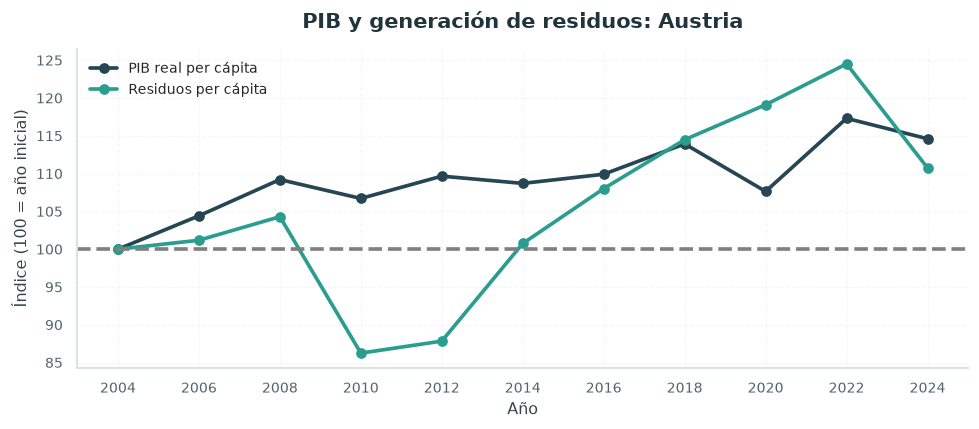

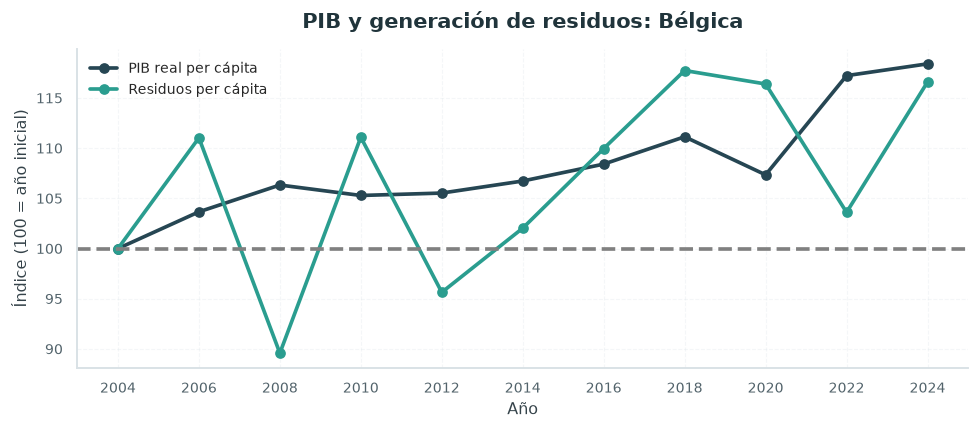

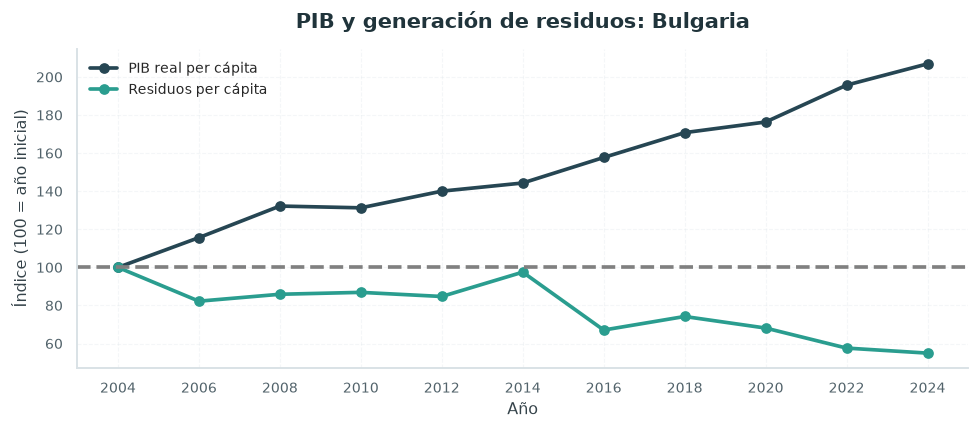

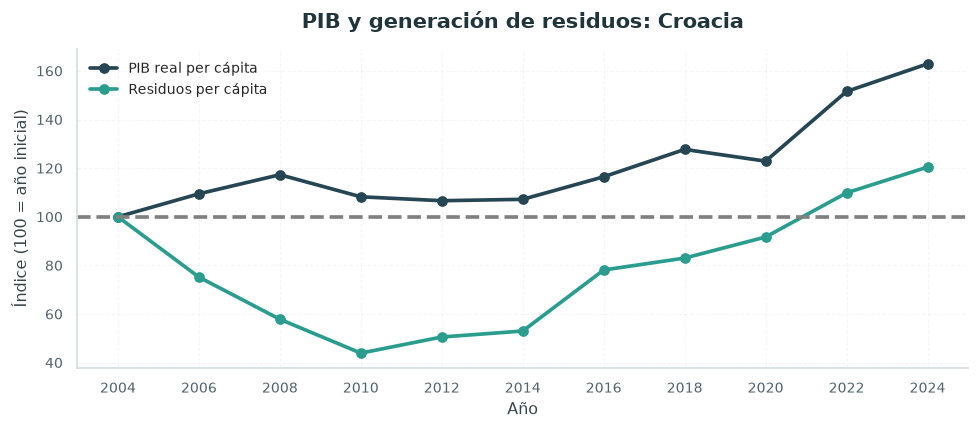

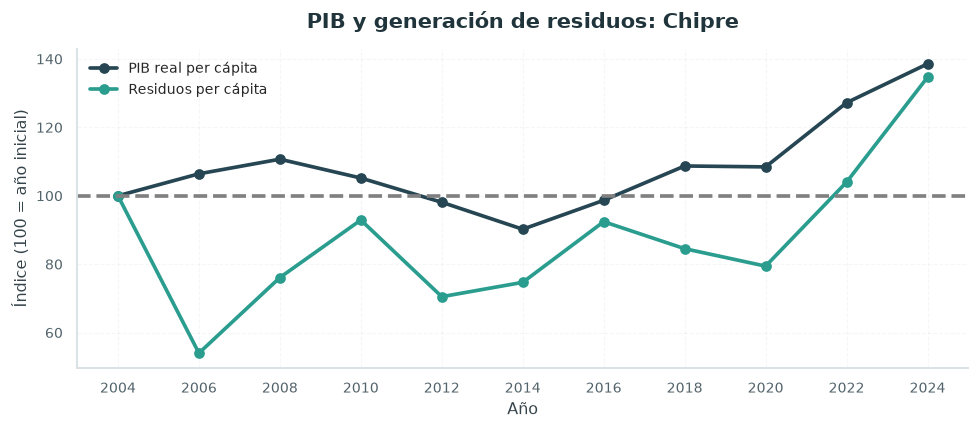

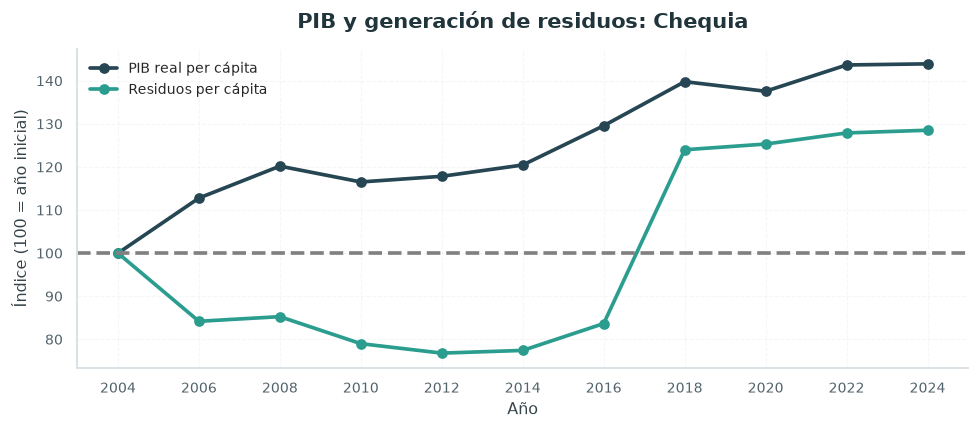

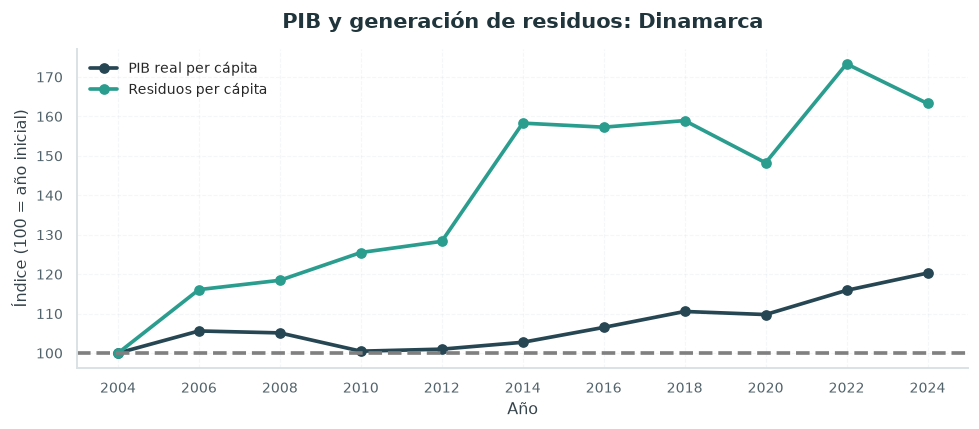

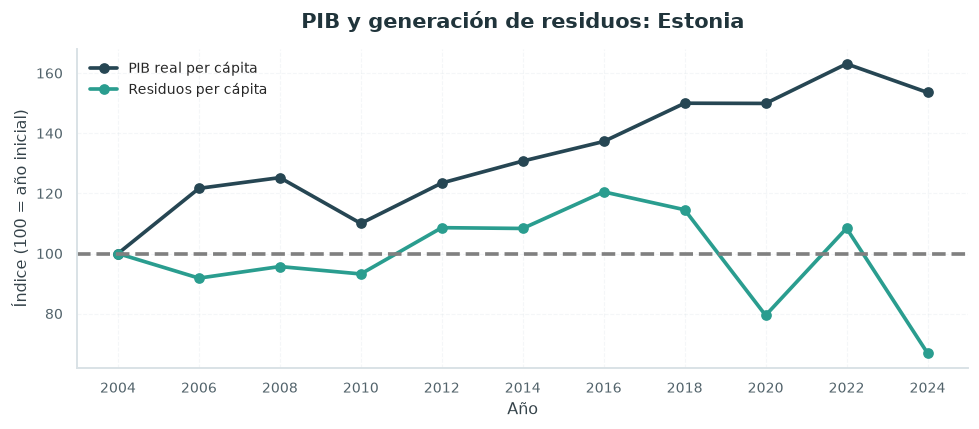

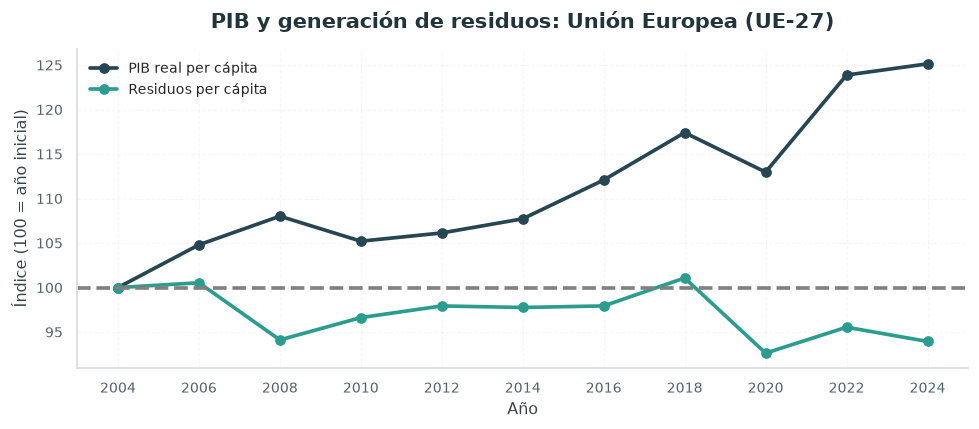

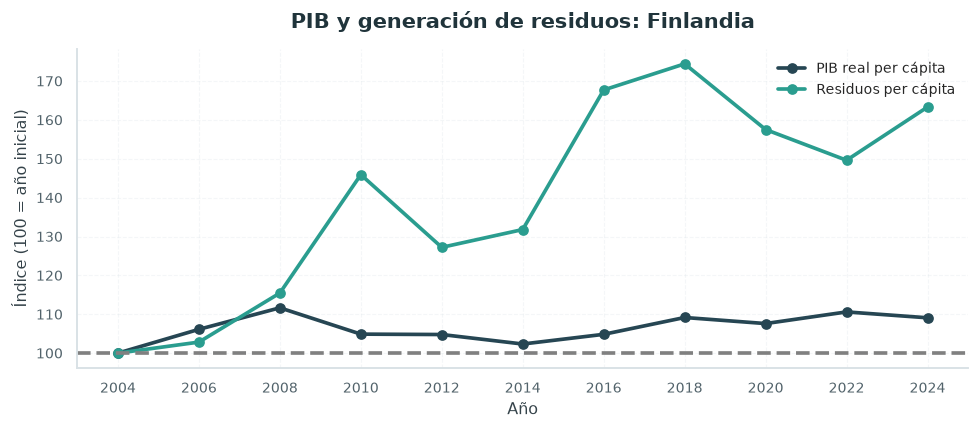

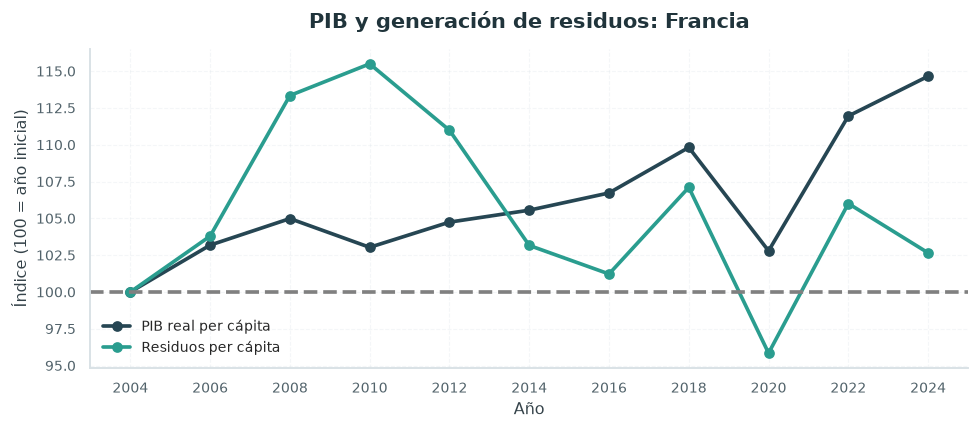

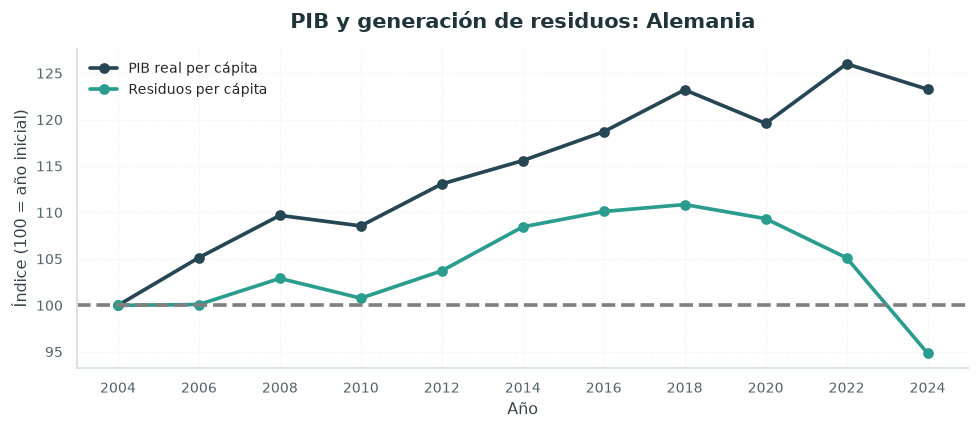

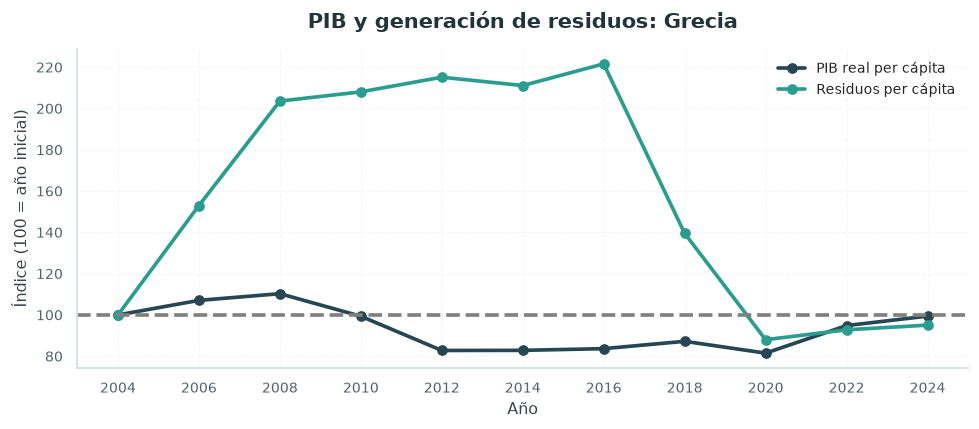

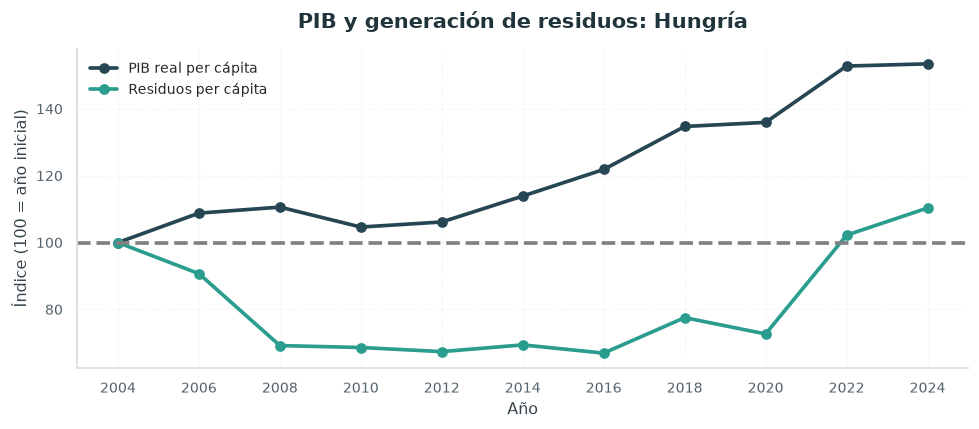

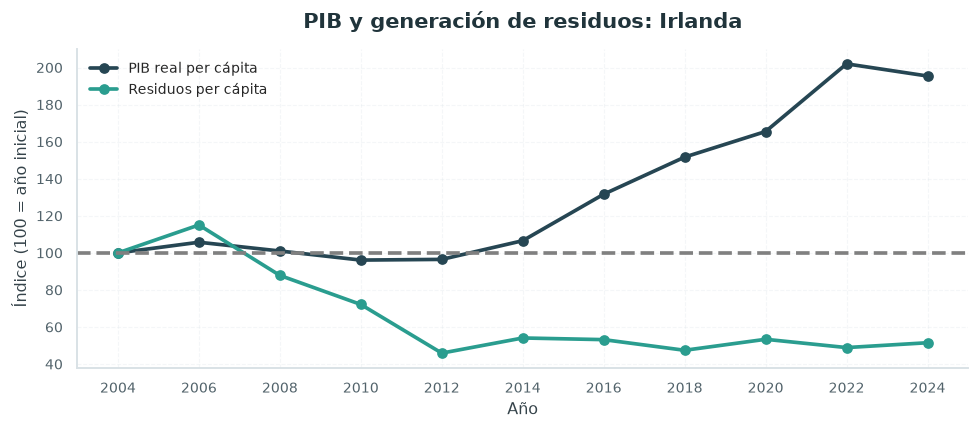

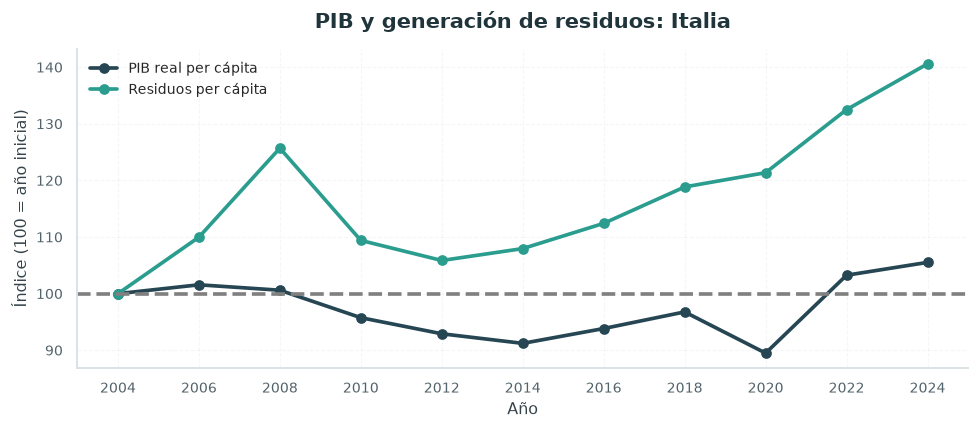

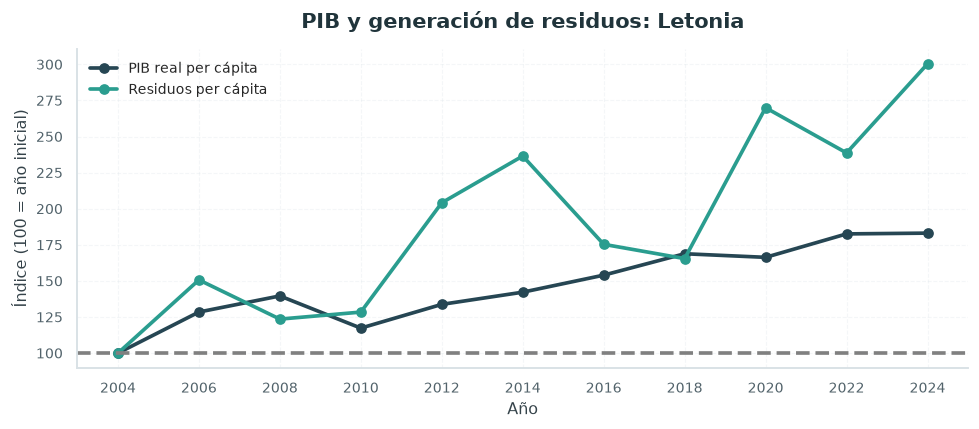

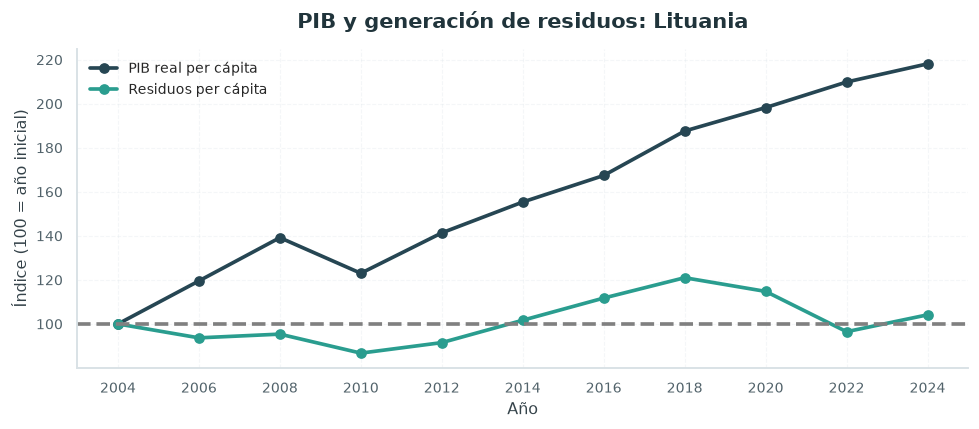

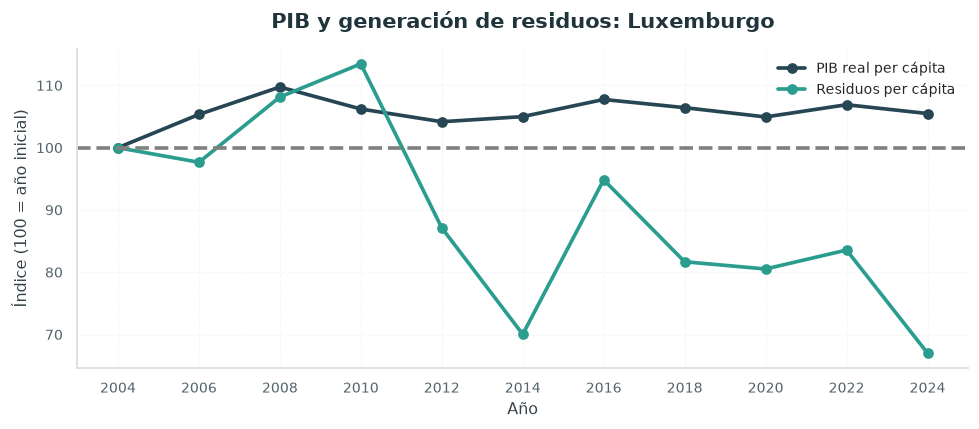

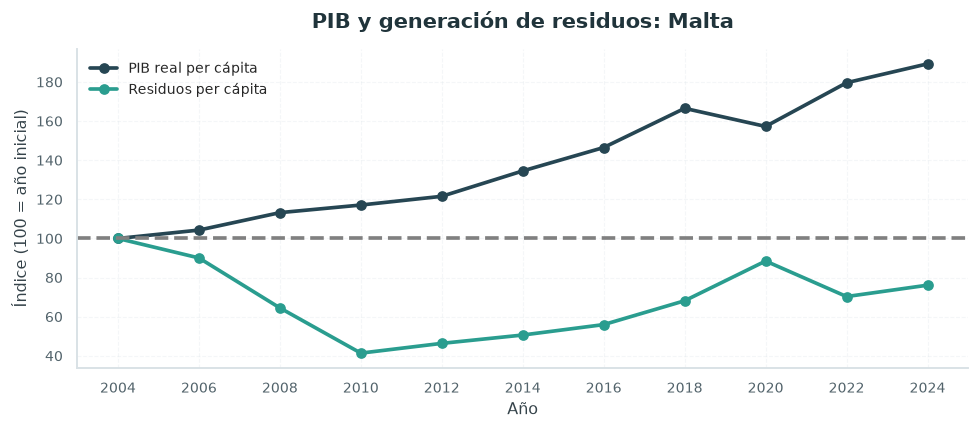

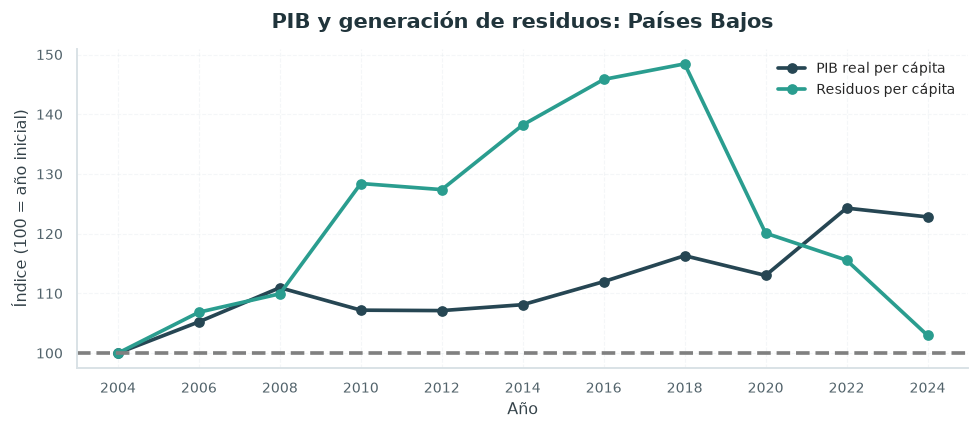

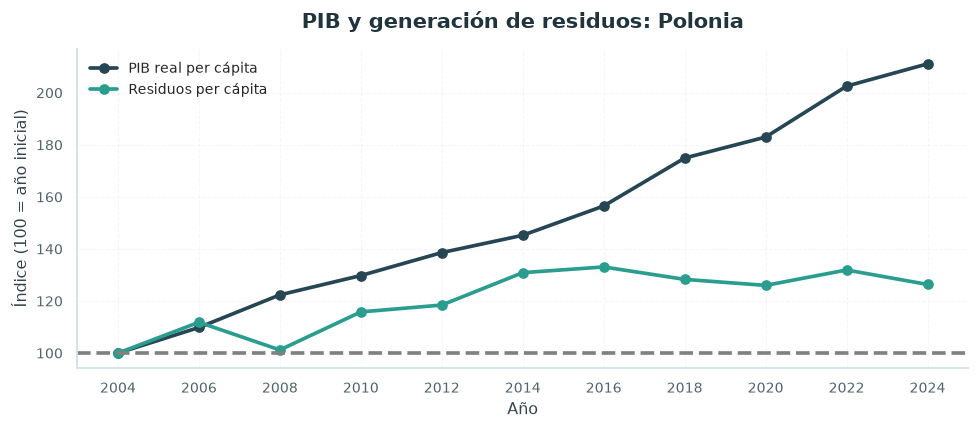

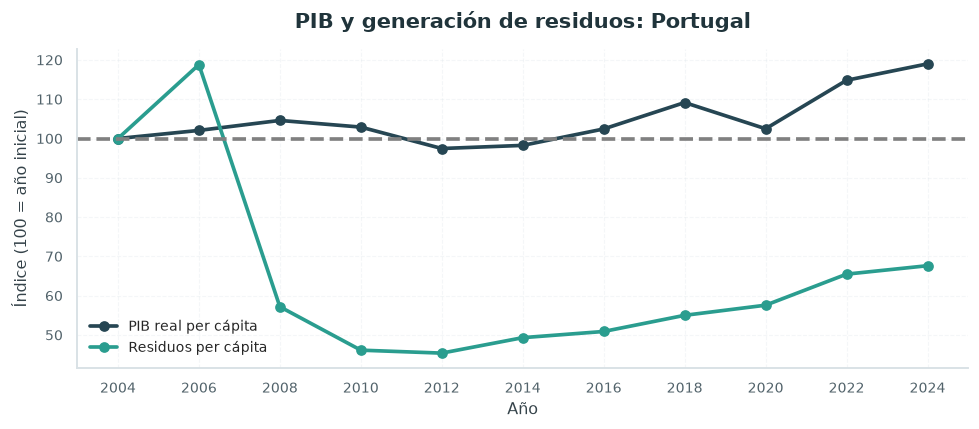

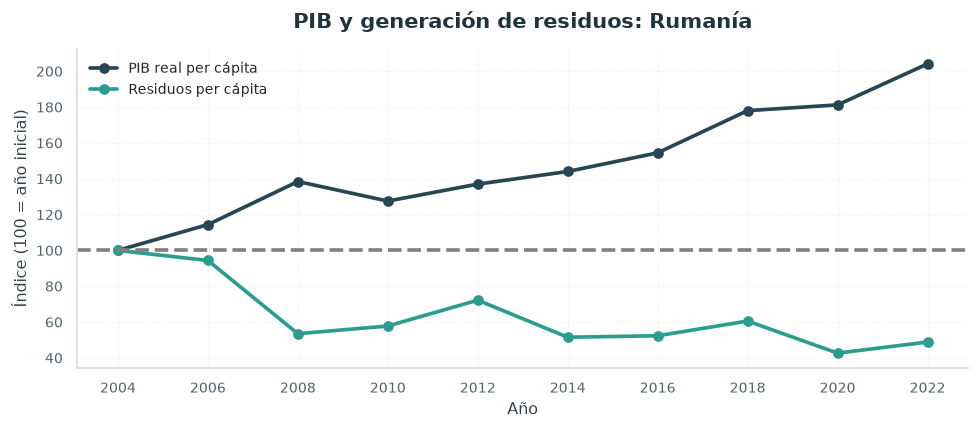

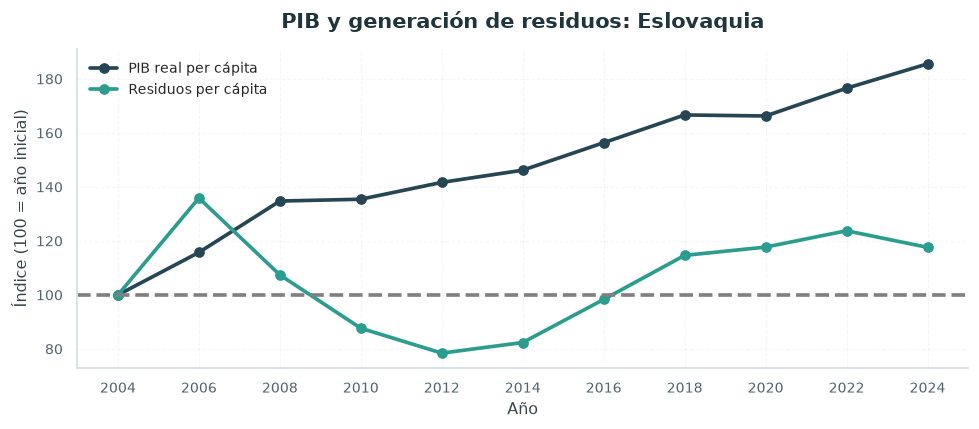

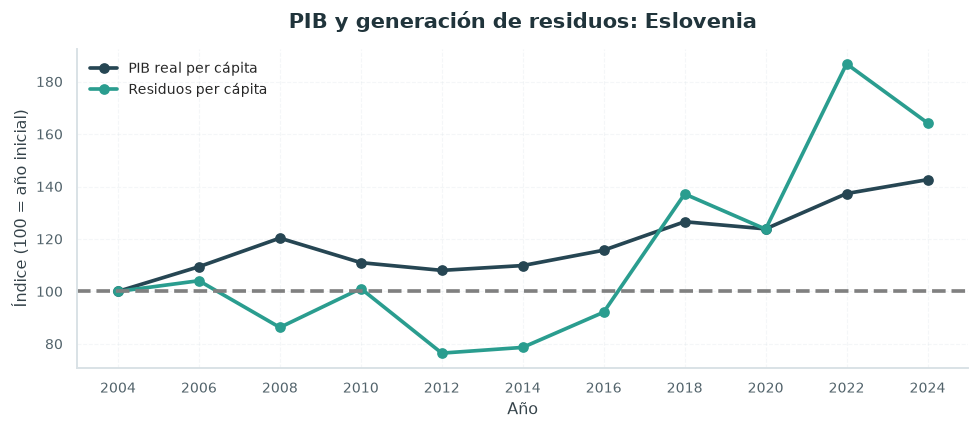

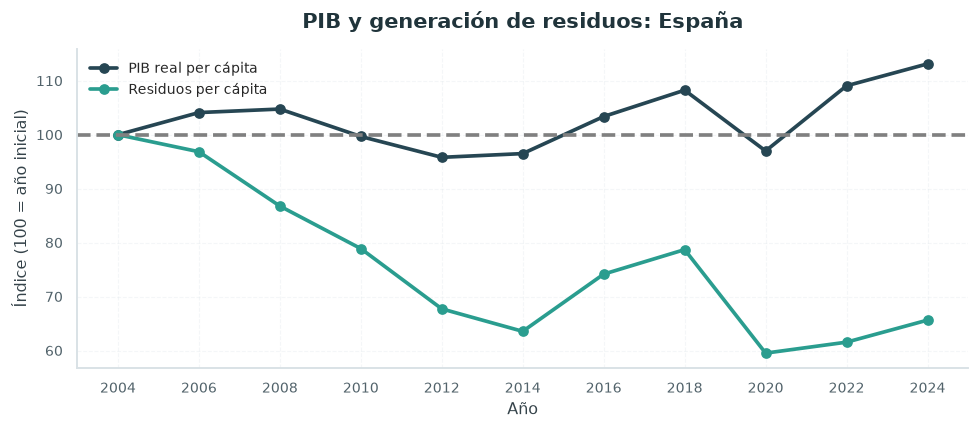

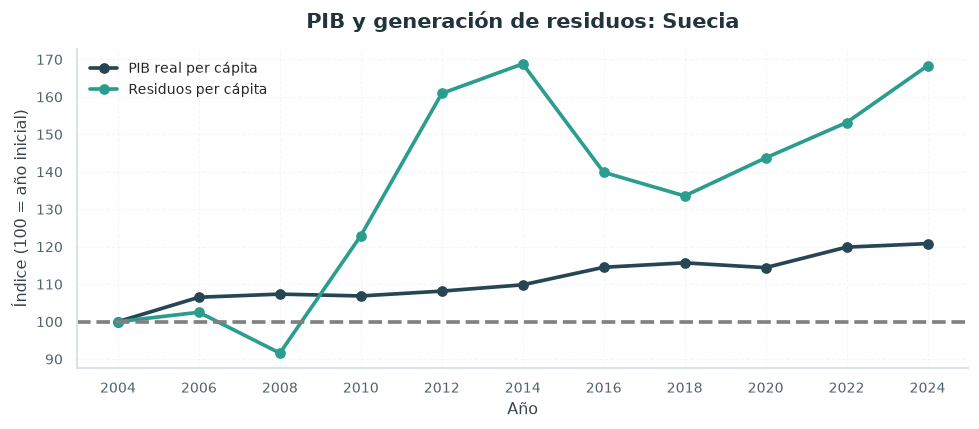

In [37]:
paises = residuos_gdp['pais'].unique()

for pais in paises:

    datos = residuos_gdp[residuos_gdp['pais'] == pais]

    plt.figure(figsize=(9, 4))

    plt.plot(
        datos['year'],
        datos['gdp_index'],
        marker='o',
        label='PIB real per cápita'
    )

    plt.plot(
        datos['year'],
        datos['waste_index'],
        marker='o',
        label='Residuos per cápita'
    )

    plt.axhline(100, color='gray', linestyle='--')

    plt.title(f'PIB y generación de residuos: {pais}')
    plt.xlabel('Año')
    plt.ylabel('Índice (100 = año inicial)')

    plt.xticks(datos["year"])

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.show()

In [38]:
# Calculamos las correlaciones
correlacion = residuos_gdp.groupby('pais').apply(
    lambda x: x['gdp_pc'].corr(x['kg_per_capita'])
)

print(correlacion.sort_values())

pais
Bulgaria                -0.886917
Rumanía                 -0.763622
Irlanda                 -0.530779
Unión Europea (UE-27)   -0.418417
Grecia                  -0.118281
Estonia                 -0.083652
Malta                   -0.016258
Portugal                 0.011160
España                   0.025610
Francia                  0.026402
Países Bajos             0.069722
Luxemburgo               0.144987
Eslovaquia               0.213954
Bélgica                  0.370473
Finlandia                0.388472
Alemania                 0.399563
Hungría                  0.488255
Italia                   0.523467
Lituania                 0.550734
Austria                  0.554329
Suecia                   0.657526
Chipre                   0.690943
Croacia                  0.722615
Dinamarca                0.723105
Chequia                  0.741719
Polonia                  0.772728
Letonia                  0.778579
Eslovenia                0.850100
dtype: float64


In [39]:
resultados = []

for pais, datos in residuos_gdp.groupby('pais'):

    datos = datos.sort_values('year')

    pib_inicial = datos['gdp_pc'].iloc[0]
    pib_final = datos['gdp_pc'].iloc[-1]

    residuos_iniciales = datos['kg_per_capita'].iloc[0]
    residuos_finales = datos['kg_per_capita'].iloc[-1]

    crecimiento_pib = (
        (pib_final / pib_inicial) - 1
    ) * 100

    crecimiento_residuos = (
        (residuos_finales / residuos_iniciales) - 1
    ) * 100

    resultados.append({
        'pais': pais,
        'crecimiento_pib': crecimiento_pib,
        'crecimiento_residuos': crecimiento_residuos
    })

desacoplamiento = pd.DataFrame(resultados)

In [40]:
def clasificar_desacoplamiento(fila):

    pib = fila['crecimiento_pib']
    residuos = fila['crecimiento_residuos']

    if pib > 0 and residuos < 0:
        return 'Desacoplamiento absoluto'

    elif pib > residuos and residuos >= 0:
        return 'Desacoplamiento relativo'

    elif pib > 0 and residuos > pib:
        return 'Acoplamiento expansivo'

    elif pib <= 0 and residuos <= 0:
        return 'Contracción conjunta'

    else:
        return 'Otros casos'


desacoplamiento['clasificacion'] = (
    desacoplamiento.apply(
        clasificar_desacoplamiento,
        axis=1
    )
)

desacoplamiento

,pais,crecimiento_pib,crecimiento_residuos,clasificacion
0,Alemania,23.270263,-5.145059,Desacoplamiento absoluto
1,Austria,14.613831,10.758323,Desacoplamiento relativo
2,Bulgaria,106.890130,-45.013436,Desacoplamiento absoluto
3,Bélgica,18.402778,16.594317,Desacoplamiento relativo
4,Chequia,43.934426,28.526646,Desacoplamiento relativo
5,Chipre,38.573316,34.654108,Desacoplamiento relativo
6,Croacia,62.913907,20.442319,Desacoplamiento relativo
7,Dinamarca,20.299364,63.288965,Acoplamiento expansivo
8,Eslovaquia,85.590778,17.623364,Desacoplamiento relativo
9,Eslovenia,42.618384,64.256055,Acoplamiento expansivo


## 7. Relación entre peso de la industria en el PIB y generación de residuos
Se utiliza `Data/gdp_industria.csv` con columnas `pais`, `year` e `industria %PIB` para 2024.

In [41]:
gdp_industria = pd.read_csv('./Data/gdp_industria.csv')

gdp_industria.head()

,pais,year,industria %PIB
0,Austria,2000,22.1
1,Austria,2001,22.2
2,Austria,2002,21.6
3,Austria,2003,21.4
4,Austria,2004,21.3


In [42]:
residuos_gdp_ind = pd.merge(todo_ue_general, gdp_industria, on=["pais", "year"], how="left")

residuos_gdp_ind.head()

,pais,year,kg_per_capita,toneladas,obs_flag,conf_status,industria %PIB
0,Austria,2004,6488.0,53020950.0,NaN,NaN,21.3
1,Austria,2006,6565.0,54286603.0,NaN,NaN,21.7
2,Austria,2008,6767.0,56308766.0,NaN,NaN,21.3
3,Austria,2010,5596.0,46799579.0,NaN,NaN,20.3
4,Austria,2012,5699.0,48045089.0,NaN,NaN,20.5


In [43]:
residuos_gdp_ind_2024 = residuos_gdp_ind[residuos_gdp_ind["year"] == 2024].copy()

In [44]:
residuos_gdp_ind_2024.head()

,pais,year,kg_per_capita,toneladas,obs_flag,conf_status,industria %PIB
10,Austria,2024,7186.0,65950580.0,NaN,NaN,18.9
21,Bélgica,2024,5909.0,70027617.0,NaN,NaN,13.9
32,Bulgaria,2024,14324.0,92268191.0,NaN,NaN,17.0
43,Croacia,2024,2015.0,7793475.0,NaN,NaN,14.4
54,Chipre,2024,4146.0,4040959.0,NaN,NaN,6.5


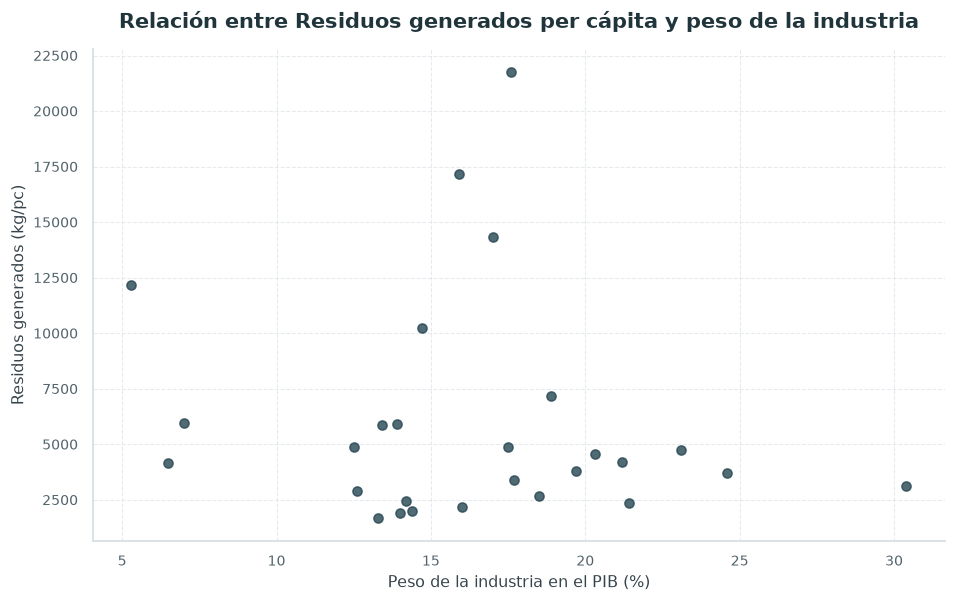

In [45]:
sns.regplot(
    data=residuos_gdp_ind_2024,
    x="industria %PIB",
    y="kg_per_capita",
    fit_reg= False
)

plt.xlabel("Peso de la industria en el PIB (%)")
plt.ylabel("Residuos generados (kg/pc)")
plt.title("Relación entre Residuos generados per cápita y peso de la industria")

plt.show()

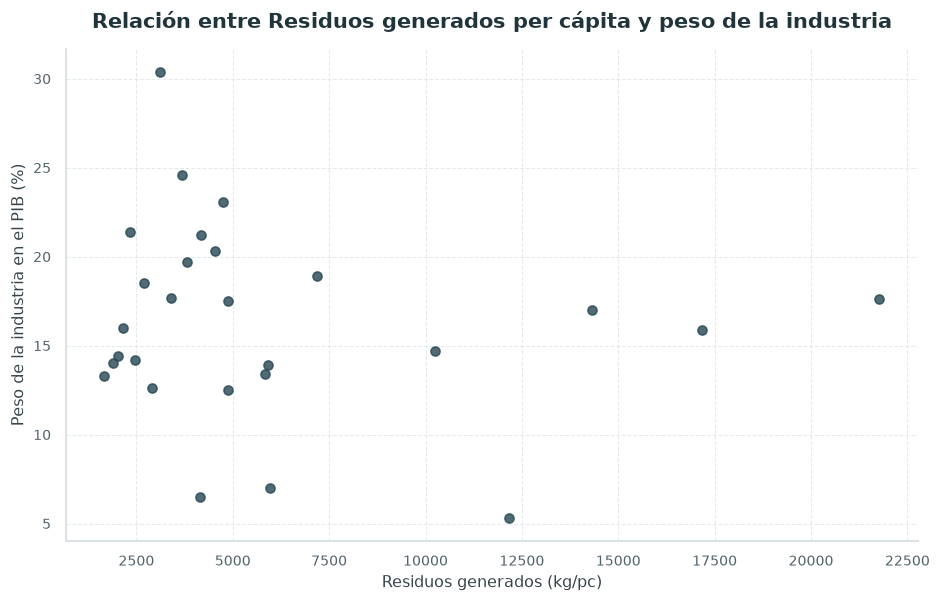

In [46]:
sns.regplot(
    data=residuos_gdp_ind_2024,
    x="kg_per_capita",
    y="industria %PIB",
    fit_reg= False
)

plt.xlabel("Residuos generados (kg/pc)")
plt.ylabel("Peso de la industria en el PIB (%)")
plt.title("Relación entre Residuos generados per cápita y peso de la industria")

plt.show()

In [47]:
# Correlación de Pearson
pearson_corr, pearson_p = pearsonr(
    residuos_gdp_ind_2024["kg_per_capita"],
    residuos_gdp_ind_2024["industria %PIB"]
)

# Correlación de Spearman
spearman_corr, spearman_p = spearmanr(
    residuos_gdp_ind_2024["kg_per_capita"],
    residuos_gdp_ind_2024["industria %PIB"]
)

print("CORRELACIÓN DE PEARSON")
print(f"Coeficiente: {pearson_corr:.3f}")
print(f"P-valor: {pearson_p:.4f}")

print("\nCORRELACIÓN DE SPEARMAN")
print(f"Coeficiente: {spearman_corr:.3f}")
print(f"P-valor: {spearman_p:.4f}")

CORRELACIÓN DE PEARSON
Coeficiente: -0.137
P-valor: 0.4953

CORRELACIÓN DE SPEARMAN
Coeficiente: -0.100
P-valor: 0.6214


## 8. Resumen de hipótesis
- **Aumento de generación:** No podemos afirmar que haya habido un aumento en la generación de residuos en la UE.
- **Menor proporción peligrosa:** el análisis muestra justo lo contrario: cada vez la proporción de residuos peligrosos es mayor.
- **Comparación por países**: Destaca Estonia. Al parecer, es por el oil-shale (a lo que debe ponerle fin debido a políticas climáticas de la UE entre 2030 y 2035).
- **Crecimiento económico:** no parece haber relación.
- **Industria:** tampoco parece haber relación entre el peso de la industria en la economía y la generación de residuos.
- **Actividades:** se ven diferencias entre las distintas actividades, siendo la construcción la actividad que más residuos genera.
